In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import joblib
import os 

In [2]:
df = pd.read_csv(r'../datasets/heart.csv')

In [3]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [4]:
# df.shape  
# df.columns 
# df.info() 
# df.isnull().sum() 
df.head(10) 
# df.tail(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


In [5]:
df['target'].value_counts()
df['target'].value_counts(normalize= True)*100

target
1    54.455446
0    45.544554
Name: proportion, dtype: float64

In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
df.describe() 

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
for col in df.columns:
    print(col, ":", df[col].unique()) 

age : [63 37 41 56 57 44 52 54 48 49 64 58 50 66 43 69 59 42 61 40 71 51 65 53
 46 45 39 47 62 34 35 29 55 60 67 68 74 76 70 38 77]
sex : [1 0]
cp : [3 2 1 0]
trestbps : [145 130 120 140 172 150 110 135 160 105 125 142 155 104 138 128 108 134
 122 115 118 100 124  94 112 102 152 101 132 148 178 129 180 136 126 106
 156 170 146 117 200 165 174 192 144 123 154 114 164]
chol : [233 250 204 236 354 192 294 263 199 168 239 275 266 211 283 219 340 226
 247 234 243 302 212 175 417 197 198 177 273 213 304 232 269 360 308 245
 208 264 321 325 235 257 216 256 231 141 252 201 222 260 182 303 265 309
 186 203 183 220 209 258 227 261 221 205 240 318 298 564 277 214 248 255
 207 223 288 160 394 315 246 244 270 195 196 254 126 313 262 215 193 271
 268 267 210 295 306 178 242 180 228 149 278 253 342 157 286 229 284 224
 206 167 230 335 276 353 225 330 290 172 305 188 282 185 326 274 164 307
 249 341 407 217 174 281 289 322 299 300 293 184 409 259 200 327 237 218
 319 166 311 169 187 176 241 131]
fbs :

In [9]:
df[df.duplicated(keep=False)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [10]:
df = df.drop_duplicates() 

In [11]:
df.shape 

(302, 14)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [14]:
# df["target"].value_counts()
df["target"].value_counts(normalize=True) * 100

target
1    54.304636
0    45.695364
Name: proportion, dtype: float64

In [15]:
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index()) 


sex:
sex
0     96
1    206
Name: count, dtype: int64

cp:
cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64

fbs:
fbs
0    257
1     45
Name: count, dtype: int64

restecg:
restecg
0    147
1    151
2      4
Name: count, dtype: int64

exang:
exang
0    203
1     99
Name: count, dtype: int64

slope:
slope
0     21
1    140
2    141
Name: count, dtype: int64

ca:
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

thal:
thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64


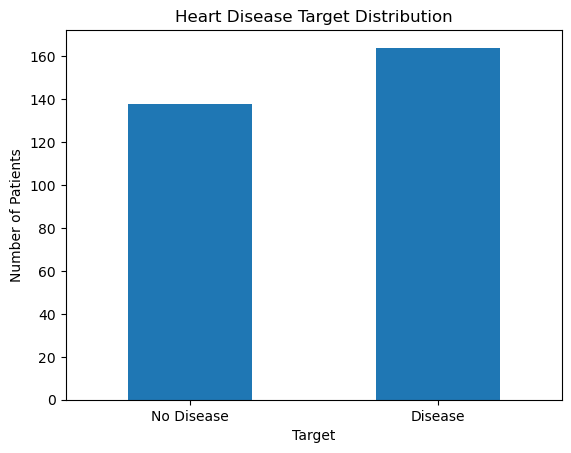

In [16]:
df['target'].value_counts().sort_index().plot(kind='bar')

plt.title('Heart Disease Target Distribution')
plt.xlabel('Target')
plt.ylabel('Number of Patients')
plt.xticks([0,1], ['No Disease', 'Disease'], rotation= 0) 
plt.show()

In [17]:
df.groupby("target")[["age", "trestbps", "chol", "thalach", "oldpeak"]].mean() 

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0,56.601449,134.398551,251.086957,139.101449,1.585507
1,52.585366,129.250000,242.640244,158.378049,0.586585


In [18]:
df.groupby("target")["cp"].value_counts() 
df.groupby("target")["ca"].value_counts() 

target  ca
0       0      45
        1      44
        2      31
        3      17
        4       1
1       0     130
        1      21
        2       7
        3       3
        4       3
Name: count, dtype: int64

In [19]:
X = df.drop("target", axis=1)
y = df["target"] 

print("X shape:", X.shape)
print("y shape:", y.shape) 

X shape: (302, 13)
y shape: (302,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size= 0.2, 
    random_state= 42, 
    stratify= y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (241, 13)
X_test: (61, 13)
y_train: (241,)
y_test: (61,)


In [21]:
numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

In [22]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [23]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(random_state=42, max_iter=1000))
])

logistic_model.fit(X_train, y_train)
y_pred_lr = logistic_model.predict(X_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      accuracy_lr * 100)

print(classification_report(y_test, y_pred_lr))

cm_lr = confusion_matrix(y_test, y_pred_lr)

print(cm_lr)

Logistic Regression Accuracy: 85.24590163934425
              precision    recall  f1-score   support

           0       0.85      0.82      0.84        28
           1       0.85      0.88      0.87        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

[[23  5]
 [ 4 29]]


In [24]:
# random forest 
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      accuracy_rf * 100)

print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

Random Forest Accuracy: 78.68852459016394
              precision    recall  f1-score   support

           0       0.83      0.68      0.75        28
           1       0.76      0.88      0.82        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.78        61

[[19  9]
 [ 4 29]]


In [25]:
# cross validation score 
lr_cv = cross_val_score(
    logistic_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

rf_cv = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Logistic Regression CV scores:", lr_cv)
print("Random Forest CV scores:", rf_cv)

print("Logistic Regression Mean CV Accuracy:",
      lr_cv.mean() * 100)

print("Random Forest Mean CV Accuracy:",
      rf_cv.mean() * 100)

Logistic Regression CV scores: [0.86885246 0.90163934 0.81666667 0.85       0.78333333]
Random Forest CV scores: [0.83606557 0.91803279 0.8        0.83333333 0.78333333]
Logistic Regression Mean CV Accuracy: 84.40983606557377
Random Forest Mean CV Accuracy: 83.4153005464481


In [26]:
joblib.dump(
    logistic_model,
    "../models/heart_disease_model.pkl"
)

['../models/heart_disease_model.pkl']

In [27]:
print(os.path.exists("../models/heart_disease_model.pkl"))

True


In [28]:
heart_model = joblib.load(
    '../models/heart_disease_model.pkl'
)

print('model loaded successfully')

patient = X.iloc[[0]]

print(patient) 

prediction = heart_model.predict(patient)

print("Predicted class:", prediction[0])

probability = heart_model.predict_proba(patient)

print(probability)

disease_probability = probability[0][1]

print("Disease probability:",
      disease_probability * 100)

actual = y.iloc[0]

print("Actual:", actual)
print("Predicted:", prediction[0])

actual_label = "Heart Disease" if actual == 1 else "No Heart Disease"
predicted_label = "Heart Disease" if prediction[0] == 1 else "No Heart Disease"

print("Actual:", actual_label)
print("Predicted:", predicted_label)

def predict_heart_disease(patient_data):
    prediction = heart_model.predict(patient_data)[0]
    probability = heart_model.predict_proba(patient_data)[0][1]

    if prediction == 1:
        result = "Heart Disease"
    else:
        result = "No Heart Disease"

    return result, probability

result, probability = predict_heart_disease(patient)

print("Prediction:", result)
print("Probability:", round(probability * 100, 2), "%")

model loaded successfully
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   

   ca  thal  
0   0     1  
Predicted class: 1
[[0.26642833 0.73357167]]
Disease probability: 73.3571671766216
Actual: 1
Predicted: 1
Actual: Heart Disease
Predicted: Heart Disease
Prediction: Heart Disease
Probability: 73.36 %


In [29]:
# v1

In [30]:

import joblib
from pathlib import Path

model_path = Path("../models/heart_disease_model.pkl")
saved_model = joblib.load(model_path)

print("Saved model type:", type(saved_model).__name__)

if hasattr(saved_model, "feature_names_in_"):
    print("\nExpected feature order:")
    print(list(saved_model.feature_names_in_))
else:
    print("\nThis model does not store feature names.")
    print("We will verify the order using the training notebook.")

print("\nModel loaded successfully.")


Saved model type: Pipeline

Expected feature order:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Model loaded successfully.


In [31]:
# v2

In [32]:

import joblib
import numpy as np
from pathlib import Path
from collections import Counter
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

saved_model = joblib.load(Path("../models/heart_disease_model.pkl"))

# Predict using the saved pipeline
saved_predictions = saved_model.predict(X_test)

print("Prediction counts:")
print(Counter(saved_predictions))

print("\nActual test-label counts:")
print(Counter(np.asarray(y_test).ravel()))

print("\nSaved model test accuracy:")
print(f"{accuracy_score(y_test, saved_predictions) * 100:.2f}%")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, saved_predictions))

print("\nClassification report:")
print(classification_report(y_test, saved_predictions, zero_division=0))


Prediction counts:
Counter({np.int64(1): 34, np.int64(0): 27})

Actual test-label counts:
Counter({np.int64(1): 33, np.int64(0): 28})

Saved model test accuracy:
85.25%

Confusion matrix:
[[23  5]
 [ 4 29]]

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.82      0.84        28
           1       0.85      0.88      0.87        33

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



In [33]:
# v3 

In [34]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

saved_model = joblib.load(Path("../models/heart_disease_model.pkl"))
predictions = saved_model.predict(X_test)

# Find one example for each predicted class
positive_index = next(i for i, p in enumerate(predictions) if p == 1)
negative_index = next(i for i, p in enumerate(predictions) if p == 0)

for label, index in [
    ("PREDICTED HEART DISEASE", positive_index),
    ("PREDICTED NO HEART DISEASE", negative_index)
]:
    sample = X_test.iloc[[index]]
    prediction = predictions[index]

    actual = (
        y_test.iloc[index]
        if hasattr(y_test, "iloc")
        else np.asarray(y_test).ravel()[index]
    )

    print(f"\n--- {label} ---")
    print("Input values:")
    print(sample.iloc[0].to_dict())
    print("Actual dataset label:", actual)
    print("Saved model prediction:", prediction)



--- PREDICTED HEART DISEASE ---
Input values:
{'age': 60.0, 'sex': 1.0, 'cp': 2.0, 'trestbps': 140.0, 'chol': 185.0, 'fbs': 0.0, 'restecg': 0.0, 'thalach': 155.0, 'exang': 0.0, 'oldpeak': 3.0, 'slope': 1.0, 'ca': 0.0, 'thal': 2.0}
Actual dataset label: 0
Saved model prediction: 1

--- PREDICTED NO HEART DISEASE ---
Input values:
{'age': 57.0, 'sex': 1.0, 'cp': 0.0, 'trestbps': 150.0, 'chol': 276.0, 'fbs': 0.0, 'restecg': 0.0, 'thalach': 112.0, 'exang': 1.0, 'oldpeak': 0.6, 'slope': 1.0, 'ca': 1.0, 'thal': 1.0}
Actual dataset label: 0
Saved model prediction: 0
